In [1]:
## AVIRIS-NG band-ratio and full-spectrum LAI analysis in Fynbos shrublands
## Author: Ramesh Bhatta, RIT
## Contact: rb1005@rit.edu

"""
This notebook documents the final raw AVIRIS-NG full-spectrum analysis used in the revised paper.
It focuses on the 20 field LAI plots, water-vapor-masked wavelength-pair screening, selection stability,
and single-index LAI relationships. Multi-index models from the original submission are not used.
"""

import os, numpy as np, pandas as pd, geopandas as gpd, matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib import cm
import rasterio
from rasterio.mask import mask
from netCDF4 import Dataset
from scipy.stats import pearsonr
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from pathlib import Path
from shapely.geometry import box
from IPython.display import display

pd.set_option("display.max_columns", 80); pd.set_option("display.width", 180)

shapefile_path = "./ground_LAI_data_processed/5mx5m_LAI_plots.shp"
raster_files = [
    "../../AVIRIS_NG_data/ang20231031t092656_002_L2B_OE_0b4f48b4_RFL_ORT_tbg_v1.nc",
    "../../AVIRIS_NG_data/ang20231109t062226_001_L2B_OE_0b4f48b4_RFL_ORT_tbg_v1.nc",
    "../../AVIRIS_NG_data/ang20231109t062226_002_L2B_OE_0b4f48b4_RFL_ORT_tbg_v1.nc",
    "../../AVIRIS_NG_data/ang20231117t123306_001_L2B_OE_0b4f48b4_RFL_ORT_tbg_v1.nc",
]

missing_aviris = [p for p in raster_files if not Path(p).exists()]
if missing_aviris:
    raise FileNotFoundError(
        "AVIRIS-NG files were not found at the expected external-data location:\n  - "
        + "\n  - ".join(missing_aviris)
        + "\nThe v2 notebooks expect AVIRIS_NG_data one directory above the GitHub repository."
    )

gdf = gpd.read_file(shapefile_path).copy()
gdf["plot_id"] = gdf["plot_id"].replace({"GBS17": "GBS16N"})
print(f"Field LAI plots: {len(gdf)}")

Field LAI plots: 20


In [2]:
## A1. Extract raw AVIRIS-NG spectra at the field LAI plots

# Create a dictionary to hold candidate spectra for each plot
candidates = {pid: [] for pid in gdf['plot_id'].unique()}
wavelengths = None

print(f"Starting Extraction for {len(gdf)} plots...")

# Main loop through raster files
for nc_file in raster_files:
    if os.path.exists(nc_file):
        actual_path = nc_file
    elif os.path.exists(os.path.basename(nc_file)):
        actual_path = os.path.basename(nc_file)
    else:
        raise FileNotFoundError(f"Missing AVIRIS-NG file: {nc_file}")

    netcdf_path = f"NETCDF:{actual_path}:/reflectance/reflectance"

    try:
        with rasterio.open(netcdf_path) as src:
            # 1. Capture wavelengths
            if wavelengths is None:
                with Dataset(actual_path, mode="r") as ds:
                    wavelengths = ds.groups["reflectance"].variables["wavelength"][:]

            # 2. Project plots to match raster CRS
            gdf_local = gdf.to_crs(src.crs)

            # 3. Iterate plots
            for idx, row in gdf_local.iterrows():
                geom = row.geometry
                bounds = src.bounds
                
                # Check if plot is within image extents
                if not box(bounds.left, bounds.bottom, bounds.right, bounds.top).intersects(geom):
                    continue

                try:
                    # ATTEMPT 1: Exact polygon mask
                    # all_touched=True ensures we grab pixels on the edges
                    out_image, _ = mask(src, [geom], crop=True, all_touched=True, nodata=-9999)
                    data = out_image.reshape(out_image.shape[0], -1)
                    
                    # Filter valid pixels (using band 100 as a check)
                    valid_mask = (data[100, :] > -50) 
                    valid_pixels = data[:, valid_mask]
                    
                    # ATTEMPT 2: Centroid fallback if no valid pixels from polygon
                    # If the polygon mask failed (0 pixels), grab the center pixel ONLY
                    if valid_pixels.shape[1] == 0:
                        cx, cy = geom.centroid.x, geom.centroid.y
                        r, c = src.index(cx, cy)
                        # Ensure centroid is inside the image grid
                        if 0 <= r < src.height and 0 <= c < src.width:
                            window = rasterio.windows.Window(c, r, 1, 1)
                            centroid_data = src.read(window=window).reshape(src.count, -1)
                            if np.all(centroid_data[100, :] > -50):
                                valid_pixels = centroid_data

                    # Save valid spectra if we have any
                    if valid_pixels.shape[1] > 0:
                        mean_spectrum = np.mean(valid_pixels, axis=1)
                        img_cx, img_cy = (bounds.left + bounds.right)/2, (bounds.top + bounds.bottom)/2
                        dist = np.sqrt((geom.centroid.x - img_cx)**2 + (geom.centroid.y - img_cy)**2)
                        
                        candidates[row['plot_id']].append({
                            'spectrum': mean_spectrum,
                            'dist': dist,
                            'file': os.path.basename(actual_path),
                            'pixels': valid_pixels.shape[1]
                        })
                        
                except Exception:
                    continue

    except Exception as e:
        print(f"  [ERROR] {os.path.basename(actual_path)}: {e}")

# Finalize records by picking the best spectrum for each plot
final_records = []
for pid, data_list in candidates.items():
    if not data_list:
        print(f"  [FAILED] Plot {pid}: No data found.")
        continue
    
    data_list.sort(key=lambda x: x['dist']) # Pick the nadir-most flightline
    best = data_list[0]
    
    rec = {
        'plot_id': pid, 'source_file': best['file'], 
        'dist_to_center': round(best['dist'], 1), 'pixels_used': best['pixels']
    }
    for i, val in enumerate(best['spectrum']):
        rec[f'band_{i}'] = val
    final_records.append(rec)

df_spectra = pd.DataFrame(final_records)
print(f"Extraction Complete: {len(df_spectra)} / {len(gdf)} plots.")

Starting Extraction for 20 plots...
Extraction Complete: 20 / 20 plots.


Plotting all spectral signatures...


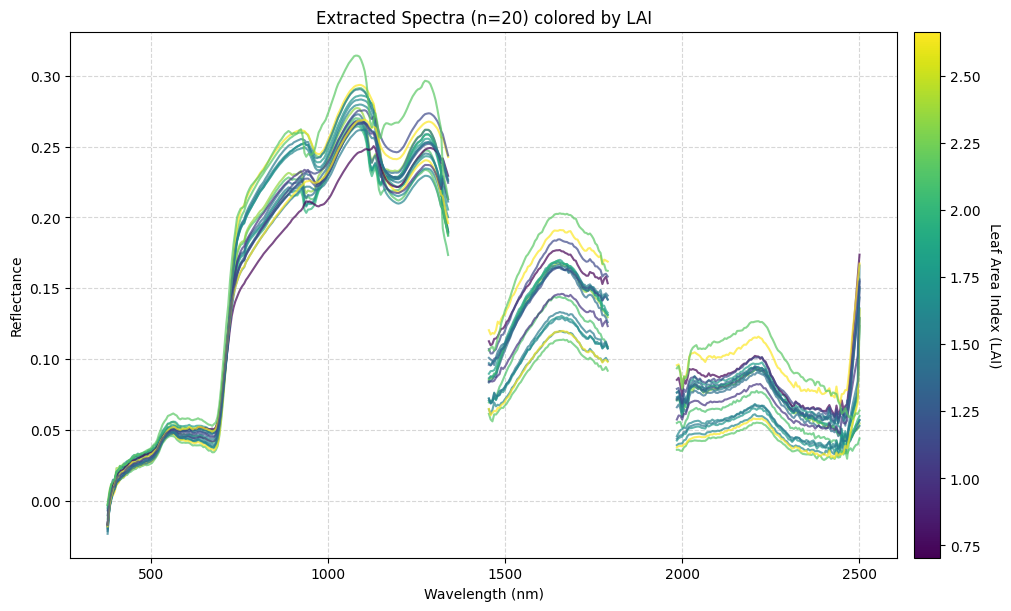

In [3]:
## A2. Visualize the extracted plot spectra

# Ensure we have the LAI values attached to the spectra
plot_data = df_spectra.merge(gdf[['plot_id', 'LAI_mean']], on='plot_id', how='left')

# Extract just the band columns for plotting
band_cols = sorted([c for c in plot_data.columns if c.startswith('band_')], 
                   key=lambda x: int(x.split('_')[1]))

X_plot = plot_data[band_cols].values
lai_values = plot_data['LAI_mean'].values

# Plotting setup
fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
norm = mcolors.Normalize(vmin=np.nanmin(lai_values), vmax=np.nanmax(lai_values)) # Color map based on LAI values
cmap = cm.viridis
print(f"Plotting all spectral signatures...")

for i in range(len(X_plot)):
    # Get spectrum and LAI
    spectrum = X_plot[i]
    lai = lai_values[i]
    
    # Mask out "bad" water absorption bands for cleaner plotting
    # Common AVIRIS-NG bad bands: ~1350-1420nm and ~1800-1950nm
    spectrum_masked = spectrum.copy()
    
    # Identify indices of water bands (approximate)
    bad_indices = np.where(
        ((wavelengths > 1340) & (wavelengths < 1450)) | 
        ((wavelengths > 1790) & (wavelengths < 1980))
    )[0]
    spectrum_masked[bad_indices] = np.nan
    
    # Plot line
    color = cmap(norm(lai))
    ax.plot(wavelengths, spectrum_masked, color=color, alpha=0.7, linewidth=1.5)
    target_wavelengths = [2005.0, 2320.6]
    for wl in target_wavelengths:
        idx = (np.abs(wavelengths - wl)).argmin()

# Add colorbar for LAI
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, orientation='vertical', pad=0.02)
cbar.set_label('Leaf Area Index (LAI)', rotation=270, labelpad=15)
ax.set_title(f"Extracted Spectra (n={len(X_plot)}) colored by LAI")
ax.set_ylabel("Reflectance")
ax.set_xlabel("Wavelength (nm)")
ax.grid(which = 'both', linestyle='--', alpha=0.5)
plt.show()

In [4]:
## B1. Define the final HSI index suite and LAI model helpers

EPS = 1e-6

def prediction_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    valid = np.isfinite(y_true) & np.isfinite(y_pred)
    y_true = y_true[valid]
    y_pred = y_pred[valid]
    if len(y_true) < 2:
        return {'n': len(y_true), 'R2': np.nan, 'RMSE': np.nan, 'MAE': np.nan, 'Bias': np.nan, 'r': np.nan}
    return {'n': len(y_true), 'R2': r2_score(y_true, y_pred), 'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)), 'MAE': mean_absolute_error(y_true, y_pred), 'Bias': float(np.mean(y_pred - y_true)), 'r': float(np.corrcoef(y_true, y_pred)[0, 1])}

def centered_r(y_true, y_pred, groups):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    groups = np.asarray(groups)
    valid = np.isfinite(y_true) & np.isfinite(y_pred) & pd.notna(groups)
    y_true = y_true[valid]
    y_pred = y_pred[valid]
    groups = groups[valid]
    yc = np.full(len(y_true), np.nan)
    pc = np.full(len(y_pred), np.nan)
    for g in np.unique(groups):
        m = groups == g
        yc[m] = y_true[m] - np.mean(y_true[m])
        pc[m] = y_pred[m] - np.mean(y_pred[m])
    if np.std(yc) <= 0 or np.std(pc) <= 0:
        return np.nan
    return float(np.corrcoef(yc, pc)[0, 1])

def fit_predict_form(x_train, y_train, x_test, form):
    degree = 1 if form == 'Linear' else 2
    coef = np.polyfit(np.asarray(x_train, dtype=float), np.asarray(y_train, dtype=float), degree)
    return np.polyval(coef, np.asarray(x_test, dtype=float))

def evaluate_single_index(x, y, form):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    valid = np.isfinite(x) & np.isfinite(y)
    x = x[valid]
    y = y[valid]
    degree = 1 if form == 'Linear' else 2
    coef = np.polyfit(x, y, degree)
    fitted = np.polyval(coef, x)
    loo = LeaveOneOut()
    cv_pred = np.full(len(y), np.nan, dtype=float)
    for tr, te in loo.split(x):
        cv_pred[te] = fit_predict_form(x[tr], y[tr], x[te], form)
    return {'n': len(y), 'Full_R2': r2_score(y, fitted), 'Full_RMSE': np.sqrt(mean_squared_error(y, fitted)), 'LOOCV_R2': r2_score(y, cv_pred), 'LOOCV_RMSE': np.sqrt(mean_squared_error(y, cv_pred)), 'LOOCV_MAE': mean_absolute_error(y, cv_pred), 'LOOCV_pred': cv_pred}

def calculate_hsi_indices(X_mat, wave_arr):
    X_mat = np.asarray(X_mat, dtype=float)
    wave_arr = np.asarray(wave_arr, dtype=float)
    targets = [480, 527.4, 531, 547.4, 550, 570, 670, 681, 709, 720, 754, 800, 850, 860, 1240, 1243.6, 1288.7, 1650, 1680, 1729.5, 1749.5, 1750, 2005, 2100, 2210, 2260, 2320.5, 2330]
    b = {w: X_mat[:, np.argmin(np.abs(wave_arr - w))] for w in targets}
    ndvi = (b[850] - b[670]) / (b[850] + b[670] + EPS)
    return {'NDVI': ndvi, 'SR': b[850] / (b[670] + EPS), 'GNDVI': (b[850] - b[550]) / (b[850] + b[550] + EPS), 'GRVI': (b[550] - b[670]) / (b[550] + b[670] + EPS), 'GDVI': b[850] - b[550], 'SAVI': 1.5 * (b[850] - b[670]) / (b[850] + b[670] + 0.5 + EPS), 'GSAVI': 1.5 * (b[850] - b[550]) / (b[850] + b[550] + 0.5 + EPS), 'OSAVI': 1.16 * (b[850] - b[670]) / (b[850] + b[670] + 0.16 + EPS), 'MSAVI2': 0.5 * (2 * b[850] + 1 - np.sqrt(np.maximum((2 * b[850] + 1) ** 2 - 8 * (b[850] - b[670]), 0))), 'NDRE': (b[850] - b[720]) / (b[850] + b[720] + EPS), 'SR_RE': b[850] / (b[720] + EPS), 'CI_RE': b[850] / (b[720] + EPS) - 1, 'MTCI': (b[754] - b[709]) / (b[709] - b[681] + EPS), 'MSR': (b[850] / (b[670] + EPS) - 1) / (np.sqrt(np.maximum(b[850] / (b[670] + EPS), 0)) + 1), 'EVI2': 2.5 * (b[850] - b[670]) / (b[850] + 2.4 * b[670] + 1 + EPS), 'NDWI': (b[860] - b[1240]) / (b[860] + b[1240] + EPS), 'CAI': 0.5 * (b[2005] + b[2210]) - b[2100], 'NDLI': (np.log(1 / (b[1750] + EPS)) - np.log(1 / (b[1680] + EPS))) / (np.log(1 / (b[1750] + EPS)) + np.log(1 / (b[1680] + EPS)) + EPS), 'Custom_SWIR_Primary': (b[2320.5] - b[2005]) / (b[2320.5] + b[2005] + EPS), 'Custom_NIR_Plateau': (b[1288.7] - b[1243.6]) / (b[1288.7] + b[1243.6] + EPS), 'Custom_VIS_Green': (b[547.4] - b[527.4]) / (b[547.4] + b[527.4] + EPS), 'Custom_SWIR1_Bridge': (b[1749.5] - b[1729.5]) / (b[1749.5] + b[1729.5] + EPS), 'NIRv': ndvi * b[850], 'SATVI': 1.5 * (b[1650] - b[670]) / (b[1650] + b[670] + 0.5 + EPS) - b[2210] / 2.0, 'NDTI': (b[1650] - b[2210]) / (b[1650] + b[2210] + EPS), 'SINDRI': (b[2210] - b[2260]) / (b[2210] + b[2260] + EPS), 'LCA': 100 * (2.0 * b[2210] - (b[2100] + b[2330])), 'MTVI2': 1.5 * (1.2 * (b[800] - b[550]) - 2.5 * (b[670] - b[550])) / np.sqrt(np.maximum((2 * b[800] + 1) ** 2 - (6 * b[800] - 5 * np.sqrt(np.maximum(b[670], 0))) - 0.5, EPS))}

def calculate_uas_indices(G, R, RE, NIR):
    G = np.asarray(G, dtype=float)
    R = np.asarray(R, dtype=float)
    RE = np.asarray(RE, dtype=float)
    NIR = np.asarray(NIR, dtype=float)
    ndvi = (NIR - R) / (NIR + R + EPS)
    msavi_term = (2 * NIR + 1) ** 2 - 8 * (NIR - R)
    mtvi_term = (2 * NIR + 1) ** 2 - (6 * NIR - 5 * np.sqrt(np.maximum(R, 0))) - 0.5
    return {'NDVI': ndvi, 'SR': NIR / (R + EPS), 'GNDVI': (NIR - G) / (NIR + G + EPS), 'GRVI': (G - R) / (G + R + EPS), 'GDVI': NIR - G, 'SAVI': 1.5 * (NIR - R) / (NIR + R + 0.5 + EPS), 'GSAVI': 1.5 * (NIR - G) / (NIR + G + 0.5 + EPS), 'OSAVI': 1.16 * (NIR - R) / (NIR + R + 0.16 + EPS), 'MSAVI2': 0.5 * (2 * NIR + 1 - np.sqrt(np.maximum(msavi_term, 0))), 'NDRE': (NIR - RE) / (NIR + RE + EPS), 'SR_RE': NIR / (RE + EPS), 'CI_RE': NIR / (RE + EPS) - 1, 'MTCI': (NIR - RE) / (RE - R + EPS), 'MSR': (NIR / (R + EPS) - 1) / (np.sqrt(np.maximum(NIR / (R + EPS), 0)) + 1), 'EVI2': 2.5 * (NIR - R) / (NIR + 2.4 * R + 1 + EPS), 'NIRv': ndvi * NIR, 'MTVI2': 1.5 * (1.2 * (NIR - G) - 2.5 * (R - G)) / np.sqrt(np.maximum(mtvi_term, EPS))}
HSI_INDEX_NAMES = [
    "NDVI", "SR", "GNDVI", "GRVI", "GDVI", "SAVI", "GSAVI", "OSAVI", "MSAVI2",
    "NDRE", "SR_RE", "CI_RE", "MTCI", "MSR", "EVI2", "NDWI", "CAI", "NDLI",
    "Custom_SWIR_Primary", "Custom_NIR_Plateau", "Custom_VIS_Green", "Custom_SWIR1_Bridge",
    "NIRv", "SATVI", "NDTI", "SINDRI", "LCA", "MTVI2",
]

print(f"HSI index suite initialized: {len(HSI_INDEX_NAMES)} indices.")

# Final field-spectra aliases used below
raw_spectra_n20 = np.asarray(X_plot, float)
y_n20 = np.asarray(lai_values, float)
plot_ids_n20 = np.asarray(plot_data["plot_id"].astype(str))
wavelengths = np.asarray(wavelengths, float)

# Strong atmospheric water-vapor regions are excluded from full-spectrum screening
valid_hsi_analysis_mask = np.isfinite(wavelengths) & ~(
    ((wavelengths >= 1340) & (wavelengths <= 1450)) |
    ((wavelengths >= 1800) & (wavelengths <= 1980))
)


COMMON_UAS_IDS = [
    "GBS0619", "GBS0622", "GBS0625", "GBS0626", "GBS0627", "GBS06P",
    "GBS164", "GBS16N", "GBS16P", "GBS19P", "GBS20P",
]

raw_hsi_indices_n20 = calculate_hsi_indices(raw_spectra_n20, wavelengths)
common_mask = np.isin(plot_ids_n20, COMMON_UAS_IDS)
raw_spectra_n11 = raw_spectra_n20[common_mask]
y_n11 = y_n20[common_mask]
plot_ids_n11 = plot_ids_n20[common_mask]
raw_hsi_indices_n11 = calculate_hsi_indices(raw_spectra_n11, wavelengths)

if len(y_n11) != 11:
    raise RuntimeError(f"Expected common n=11; found {len(y_n11)}.")

def screen_single_index_models(representation_dict, y):
    rows, prediction_store = [], {}
    for representation, index_dict in representation_dict.items():
        for index_name, values in index_dict.items():
            for form in ["Linear", "Quadratic"]:
                result = evaluate_single_index(values, y, form)
                rows.append({
                    "Representation":representation, "Index":index_name, "Form":form, "n":result["n"],
                    "Full_R2":result["Full_R2"], "Full_RMSE":result["Full_RMSE"],
                    "LOOCV_R2":result["LOOCV_R2"], "LOOCV_RMSE":result["LOOCV_RMSE"],
                    "LOOCV_MAE":result["LOOCV_MAE"],
                })
                prediction_store[(representation, index_name, form)] = result
    results = pd.DataFrame(rows)
    best = (
        results.sort_values(["Representation","LOOCV_R2","LOOCV_RMSE"], ascending=[True,False,True])
        .groupby("Representation", as_index=False).first()
    )
    return results, best, prediction_store


HSI index suite initialized: 28 indices.


FULL-SPECTRUM WAVELENGTH-PAIR RESULT — DESCRIPTIVE FULL n=20
Strongest pair: 2005.02 / 2320.56 nm
r = 0.723; linear R2 = 0.522

Top 20 wavelength pairs:


,i,j,lambda_1_nm,lambda_2_nm,R2_linear,r
0,267,330,2005.016,2320.556,0.522,0.723
1,267,288,2005.016,2110.196,0.512,0.715
2,267,293,2005.016,2135.236,0.508,0.713
3,267,292,2005.016,2130.226,0.503,0.709
4,267,291,2005.016,2125.226,0.500,0.707
5,267,286,2005.016,2100.176,0.499,0.706
6,267,315,2005.016,2245.426,0.497,0.705
7,267,289,2005.016,2115.206,0.495,0.703
8,267,335,2005.016,2345.606,0.493,0.702
9,267,323,2005.016,2285.496,0.493,0.702



SELECTION-AWARE NESTED LOOCV WAVELENGTH-PAIR TEST


,held_out_plot,lambda_1_nm,lambda_2_nm,training_R2,observed_LAI,predicted_LAI
0,GBS0619,2005.016,2320.556,0.510,2.113,2.259
1,GBS0622,2005.016,2320.556,0.510,2.348,1.952
2,GBS0625,2005.016,2320.556,0.534,1.575,1.848
3,GBS0626,2005.016,2320.556,0.523,1.791,1.868
4,GBS0627,2005.016,2110.196,0.553,1.413,1.942
5,GBS06P,2005.016,2320.556,0.521,1.977,1.794
6,GBS161,2005.016,2135.236,0.522,1.604,1.888
7,GBS162,2005.016,2320.556,0.524,2.146,1.812
8,GBS164,2005.016,2320.556,0.523,1.737,1.826
9,GBS168,2005.016,2320.556,0.549,1.623,1.213


Selections within ±15 nm of BOTH full-data wavelengths: 0.700
Selections with first wavelength within ±15 nm: 0.950
Nested selection-aware performance: R2 = -0.440; RMSE = 0.616; MAE = 0.433


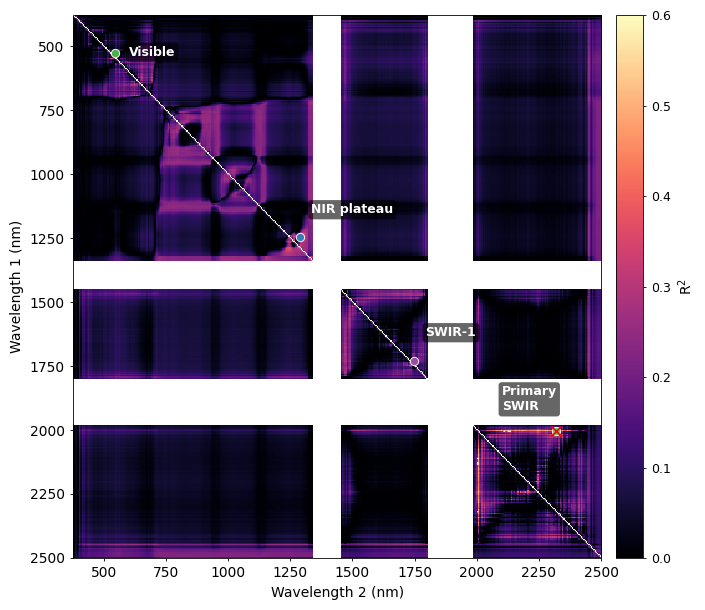

In [5]:
## C1. Full-spectrum normalized-difference wavelength-pair sensitivity

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

valid_idx = np.where(np.asarray(valid_hsi_analysis_mask, bool))[0]
W = np.asarray(wavelengths, float)[valid_idx]
S = np.asarray(raw_spectra_n20, float)[:, valid_idx]
y_pair = np.asarray(y_n20, float)
if 'pair_df' not in globals():
    pair_i, pair_j = np.triu_indices(len(W), k=1)
    nd_all = (S[:, pair_j] - S[:, pair_i]) / (S[:, pair_j] + S[:, pair_i] + EPS)
    xc = nd_all - np.mean(nd_all, axis=0, keepdims=True)
    yc = y_pair - np.mean(y_pair)
    denom = np.sqrt(np.sum(xc ** 2, axis=0) * np.sum(yc ** 2))
    r_all = np.full(len(pair_i), np.nan, float)
    ok = np.isfinite(denom) & (denom > 0)
    r_all[ok] = np.sum(xc[:, ok] * yc[:, None], axis=0) / denom[ok]
    pair_df = pd.DataFrame({'i': pair_i, 'j': pair_j, 'lambda_1_nm': W[pair_i], 'lambda_2_nm': W[pair_j], 'R2_linear': r_all ** 2, 'r': r_all}).dropna(subset=['R2_linear'])
    pair_df = pair_df.sort_values('R2_linear', ascending=False).reset_index(drop=True)
else:
    pair_df = pair_df.copy().sort_values('R2_linear', ascending=False).reset_index(drop=True)
pair_i = pair_df['i'].to_numpy(int)
pair_j = pair_df['j'].to_numpy(int)
nd_all = (S[:, pair_j] - S[:, pair_i]) / (S[:, pair_j] + S[:, pair_i] + EPS)
best_pair = pair_df.iloc[0]
best_l1 = float(best_pair['lambda_1_nm'])
best_l2 = float(best_pair['lambda_2_nm'])
best_r2 = float(best_pair['R2_linear'])
best_r = float(best_pair['r'])
wavelength_pair_top = pair_df.head(20).copy()
print('=' * 72)
print('FULL-SPECTRUM WAVELENGTH-PAIR RESULT — DESCRIPTIVE FULL n=20')
print('=' * 72)
print(f'Strongest pair: {best_l1:.2f} / {best_l2:.2f} nm')
print(f'r = {best_r:.3f}; linear R2 = {best_r2:.3f}')
print('\nTop 20 wavelength pairs:')
display(wavelength_pair_top.round(3))
nested_pred = np.full(len(y_pair), np.nan, float)
nested_rows = []
for held_out in range(len(y_pair)):
    train = np.arange(len(y_pair)) != held_out
    Xtr = nd_all[train, :]
    ytr = y_pair[train]
    finite_cols = np.all(np.isfinite(Xtr), axis=0)
    candidate_cols = np.where(finite_cols)[0]
    Xc = Xtr[:, candidate_cols]
    Xc_centered = Xc - np.mean(Xc, axis=0, keepdims=True)
    yc = ytr - np.mean(ytr)
    denom = np.sqrt(np.sum(Xc_centered ** 2, axis=0) * np.sum(yc ** 2))
    r = np.full(len(candidate_cols), np.nan, float)
    ok = np.isfinite(denom) & (denom > 0)
    r[ok] = np.sum(Xc_centered[:, ok] * yc[:, None], axis=0) / denom[ok]
    r2 = r ** 2
    if not np.any(np.isfinite(r2)):
        raise RuntimeError(f'No valid wavelength pair for held-out plot {plot_ids_n20[held_out]}.')
    local_best = int(np.nanargmax(r2))
    best_col = int(candidate_cols[local_best])
    x_train = nd_all[train, best_col]
    x_test = np.array([nd_all[held_out, best_col]], dtype=float)
    coef = np.polyfit(x_train, ytr, 1)
    nested_pred[held_out] = float(np.polyval(coef, x_test)[0])
    nested_rows.append({'held_out_plot': str(plot_ids_n20[held_out]), 'lambda_1_nm': float(W[pair_i[best_col]]), 'lambda_2_nm': float(W[pair_j[best_col]]), 'training_R2': float(r2[local_best]), 'observed_LAI': float(y_pair[held_out]), 'predicted_LAI': float(nested_pred[held_out])})
wavelength_selection_stability_nested = pd.DataFrame(nested_rows)
nested_metrics = {'n': len(y_pair), 'LOOCV_R2': r2_score(y_pair, nested_pred), 'LOOCV_RMSE': np.sqrt(mean_squared_error(y_pair, nested_pred)), 'LOOCV_MAE': mean_absolute_error(y_pair, nested_pred)}
close_both = (np.abs(wavelength_selection_stability_nested['lambda_1_nm'] - best_l1) <= 15) & (np.abs(wavelength_selection_stability_nested['lambda_2_nm'] - best_l2) <= 15)
close_first = np.abs(wavelength_selection_stability_nested['lambda_1_nm'] - best_l1) <= 15
print('\n' + '=' * 72)
print('SELECTION-AWARE NESTED LOOCV WAVELENGTH-PAIR TEST')
print('=' * 72)
display(wavelength_selection_stability_nested.round(3))
print(f'Selections within ±15 nm of BOTH full-data wavelengths: {close_both.mean():.3f}')
print(f'Selections with first wavelength within ±15 nm: {close_first.mean():.3f}')
print(f"Nested selection-aware performance: R2 = {nested_metrics['LOOCV_R2']:.3f}; RMSE = {nested_metrics['LOOCV_RMSE']:.3f}; MAE = {nested_metrics['LOOCV_MAE']:.3f}")
r2_matrix_plot = np.full((len(wavelengths), len(wavelengths)), np.nan, dtype=float)
pair_i_valid = pair_df['i'].to_numpy(int)
pair_j_valid = pair_df['j'].to_numpy(int)
pair_r2 = pair_df['R2_linear'].to_numpy(float)
pair_i_full = valid_idx[pair_i_valid]
pair_j_full = valid_idx[pair_j_valid]
r2_matrix_plot[pair_i_full, pair_j_full] = pair_r2
r2_matrix_plot[pair_j_full, pair_i_full] = pair_r2
water_regions = [(1340, 1450), (1800, 1980)]
water_mask_1d = np.zeros(len(wavelengths), dtype=bool)
for water_start, water_end in water_regions:
    water_mask_1d |= (wavelengths >= water_start) & (wavelengths <= water_end)
r2_matrix_plot[water_mask_1d, :] = np.nan
r2_matrix_plot[:, water_mask_1d] = np.nan
r2_threshold = 0.5
wl_min = float(np.nanmin(wavelengths))
wl_max = float(np.nanmax(wavelengths))
identified_pairs = [{'label': 'Primary\nSWIR', 'wl_1': 2005.0, 'wl_2': 2320.5, 'color': '#00ff66'}, {'label': 'NIR plateau', 'wl_1': 1243.6, 'wl_2': 1288.7, 'color': '#377eb8'}, {'label': 'Visible', 'wl_1': 527.4, 'wl_2': 547.4, 'color': '#4daf4a'}, {'label': 'SWIR-1', 'wl_1': 1729.5, 'wl_2': 1749.5, 'color': '#984ea3'}]
label_offsets = {'Primary\nSWIR': (-220, -75), 'NIR plateau': (45, -55), 'Visible': (55, 45), 'SWIR-1': (45, -60)}
fig, ax = plt.subplots(figsize=(7.13, 6.2))
cmap_main = mpl.colormaps['magma'].copy()
cmap_main.set_bad(color='white')
im = ax.imshow(np.ma.masked_invalid(r2_matrix_plot), extent=[wl_min, wl_max, wl_max, wl_min], origin='upper', cmap=cmap_main, vmin=0, vmax=max(0.6, float(np.nanmax(r2_matrix_plot))), interpolation='nearest', aspect='auto')
if np.nanmax(r2_matrix_plot) > r2_threshold:
    ax.contour(wavelengths, wavelengths, np.ma.masked_invalid(r2_matrix_plot), levels=[r2_threshold], colors='white', linewidths=0.65, alpha=0.85)
high_r2_mask = np.where(r2_matrix_plot >= r2_threshold, 1.0, np.nan)
cmap_high = mpl.colors.ListedColormap(['#00ffff'])
cmap_high.set_bad((1, 1, 1, 0))
ax.imshow(np.ma.masked_invalid(high_r2_mask), extent=[wl_min, wl_max, wl_max, wl_min], origin='upper', cmap=cmap_high, alpha=0.11, interpolation='nearest', aspect='auto')
ax.plot([wl_min, wl_max], [wl_min, wl_max], color='white', linewidth=0.45, alpha=0.45, zorder=4)
for pair in identified_pairs:
    x = pair['wl_2']
    y_pair_marker = pair['wl_1']
    dx, dy = label_offsets[pair['label']]
    ax.scatter(x, y_pair_marker, marker='o', s=36, facecolor=pair['color'], edgecolor='white', linewidth=0.65, zorder=7)
    ax.text(x + dx, y_pair_marker + dy - 50, pair['label'], color='white', fontsize=9, fontweight='bold', ha='left', va='center', zorder=10, bbox={'boxstyle': 'round,pad=0.25', 'facecolor': 'black', 'edgecolor': 'none', 'alpha': 0.6})
ax.scatter(best_l2, best_l1, marker='x', s=52, color='red', linewidths=1.2, zorder=9)
cbar = fig.colorbar(im, ax=ax, pad=0.025, fraction=0.052)
cbar.set_label('R$^2$')
cbar.ax.tick_params(labelsize=9, length=2.5, width=0.6)
cbar.outline.set_linewidth(0.6)
ax.set_xlabel('Wavelength 2 (nm)')
ax.set_ylabel('Wavelength 1 (nm)')
ax.tick_params(axis='both', length=2.5, width=0.6)
for spine in ax.spines.values():
    spine.set_linewidth(0.6)
fig.tight_layout()
plt.show()

RAW AVIRIS-NG HSI CORRELATIONS WITH LAI — n=20 AND COMMON n=11


,Index,n_20,r_20,p_20,n_11,r_11,p_11
0,CAI,20,-0.6690,0.0013,11,-0.8220,0.0019
1,Custom_NIR_Plateau,20,-0.6144,0.0039,11,-0.8465,0.0010
2,Custom_SWIR1_Bridge,20,-0.5956,0.0056,11,-0.8299,0.0016
3,LCA,20,-0.1806,0.4460,11,-0.2024,0.5506
4,SINDRI,20,-0.1478,0.5340,11,-0.5499,0.0797
5,SATVI,20,-0.1308,0.5826,11,-0.1997,0.5560
6,NDTI,20,0.1225,0.6070,11,-0.0179,0.9583
7,GNDVI,20,0.2028,0.3911,11,0.2730,0.4166
8,MTCI,20,0.2284,0.3327,11,0.4683,0.1463
9,NDWI,20,0.2573,0.2735,11,0.5899,0.0561


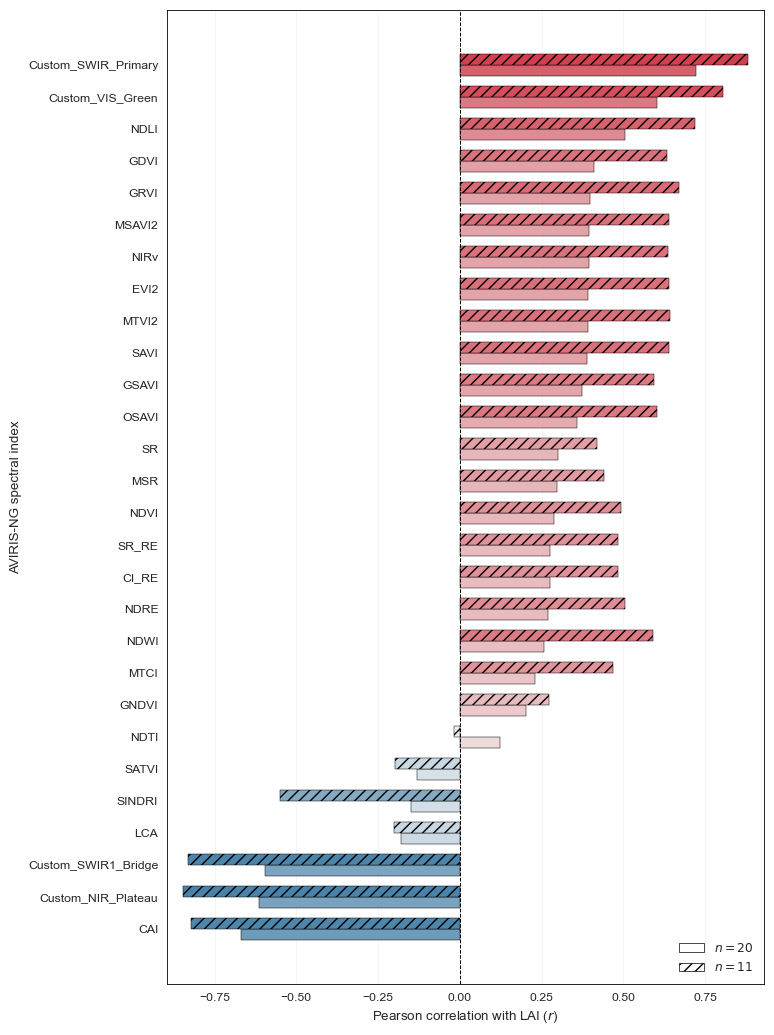


RAW HSI SINGLE-INDEX MODELS — FULL n=20, DESCRIPTIVE


,Index,Form,n,Full_R2,Full_RMSE,LOOCV_R2,LOOCV_RMSE,LOOCV_MAE
0,Custom_SWIR_Primary,Linear,20,0.522,0.355,0.427,0.388,0.316
1,Custom_SWIR1_Bridge,Quadratic,20,0.409,0.395,0.291,0.432,0.310
2,Custom_NIR_Plateau,Linear,20,0.377,0.405,0.241,0.447,0.333
3,Custom_VIS_Green,Linear,20,0.365,0.409,0.207,0.457,0.390
4,CAI,Linear,20,0.448,0.381,0.166,0.469,0.355
5,NDLI,Quadratic,20,0.288,0.433,0.083,0.491,0.362
6,NDTI,Quadratic,20,0.290,0.432,-0.012,0.516,0.415
7,GDVI,Linear,20,0.168,0.468,-0.052,0.526,0.429
8,MSAVI2,Linear,20,0.156,0.471,-0.074,0.532,0.434
9,NIRv,Linear,20,0.155,0.472,-0.074,0.532,0.434



RAW HSI SINGLE-INDEX MODELS — COMMON n=11, DESCRIPTIVE


,Index,Form,n,Full_R2,Full_RMSE,LOOCV_R2,LOOCV_RMSE,LOOCV_MAE
0,Custom_SWIR_Primary,Linear,11,0.776,0.220,0.688,0.259,0.209
1,Custom_SWIR1_Bridge,Quadratic,11,0.735,0.239,0.627,0.284,0.224
2,Custom_NIR_Plateau,Linear,11,0.717,0.247,0.617,0.287,0.237
3,NDWI,Quadratic,11,0.718,0.246,0.533,0.317,0.276
4,Custom_VIS_Green,Linear,11,0.648,0.276,0.421,0.353,0.292
5,NDRE,Quadratic,11,0.545,0.313,0.378,0.366,0.304
6,SR_RE,Quadratic,11,0.543,0.314,0.360,0.372,0.321
7,CI_RE,Quadratic,11,0.543,0.314,0.360,0.372,0.321
8,GDVI,Quadratic,11,0.550,0.311,0.295,0.390,0.353
9,GRVI,Quadratic,11,0.600,0.294,0.256,0.400,0.345


In [6]:
## C2. Raw AVIRIS-NG index correlations and single-index LAI models

from scipy.stats import pearsonr
from matplotlib.patches import Patch

def hsi_corr_table(index_dict, y):
    rows = []
    y = np.asarray(y, float)
    for index_name, values in index_dict.items():
        x = np.asarray(values, float)
        valid = np.isfinite(x) & np.isfinite(y)
        if valid.sum() < 3 or np.std(x[valid]) == 0:
            r, p = (np.nan, np.nan)
        else:
            r, p = pearsonr(x[valid], y[valid])
        rows.append({'Index': index_name, 'n': int(valid.sum()), 'r': r, 'p': p})
    return pd.DataFrame(rows)
raw_hsi_correlation_n20 = hsi_corr_table(raw_hsi_indices_n20, y_n20)
raw_hsi_correlation_n11 = hsi_corr_table(raw_hsi_indices_n11, y_n11)
raw_hsi_correlation_table_n20_n11 = raw_hsi_correlation_n20.rename(columns={'n': 'n_20', 'r': 'r_20', 'p': 'p_20'}).merge(raw_hsi_correlation_n11.rename(columns={'n': 'n_11', 'r': 'r_11', 'p': 'p_11'}), on='Index', how='inner', validate='one_to_one').sort_values('r_20', ascending=True).reset_index(drop=True)
print('=' * 72)
print('RAW AVIRIS-NG HSI CORRELATIONS WITH LAI — n=20 AND COMMON n=11')
print('=' * 72)
display(raw_hsi_correlation_table_n20_n11.round(4))
import seaborn as sns
sns.set_theme(context='paper', style='white', font='Arial', rc={'axes.edgecolor': 'black', 'axes.linewidth': 0.6, 'grid.color': '0.88', 'grid.linewidth': 0.4})
bar_palette = sns.diverging_palette(240, 10, s=85, l=45, n=256)

def get_corr_colors(values):
    return [bar_palette[int(np.clip((r + 1) / 2 * 255, 0, 255))] for r in values]
plot_df = raw_hsi_correlation_table_n20_n11.copy()
y_pos = np.arange(len(plot_df))
bar_height = 0.34
colors_n20 = get_corr_colors(plot_df['r_20'].to_numpy(float))
colors_n11 = get_corr_colors(plot_df['r_11'].to_numpy(float))
fig, ax = plt.subplots(figsize=(7.83, 10.44))
ax.barh(y_pos - bar_height / 2, plot_df['r_20'], height=bar_height, color=colors_n20, edgecolor='black', linewidth=0.35, zorder=2)
ax.barh(y_pos + bar_height / 2, plot_df['r_11'], height=bar_height, color=colors_n11, edgecolor='black', linewidth=0.35, hatch='///', zorder=2)
ax.axvline(0, color='black', linestyle='--', linewidth=0.7, zorder=3)
ax.set_yticks(y_pos)
ax.set_yticklabels(plot_df['Index'])
ax.set_xlabel('Pearson correlation with LAI ($r$)')
ax.set_ylabel('AVIRIS-NG spectral index')
all_r = np.concatenate([plot_df['r_20'].to_numpy(float), plot_df['r_11'].to_numpy(float)])
x_min = min(-0.8, float(np.nanmin(all_r)) - 0.05)
x_max = max(0.8, float(np.nanmax(all_r)) + 0.05)
ax.set_xlim(x_min, x_max)
ax.grid(axis='x', linestyle='-', linewidth=0.4, alpha=0.6)
ax.grid(axis='y', visible=False)
ax.set_axisbelow(True)
ax.tick_params(axis='both', length=2.5, width=0.6)
for spine in ax.spines.values():
    spine.set_linewidth(0.6)
legend_handles = [Patch(facecolor='white', edgecolor='black', linewidth=0.5, label='$n=20$'), Patch(facecolor='white', edgecolor='black', linewidth=0.5, hatch='///', label='$n=11$')]
ax.legend(handles=legend_handles, loc='lower right', frameon=False)
plt.tight_layout()
plt.show()
raw_hsi_screen_n20, _, raw_hsi_screen_store_n20 = screen_single_index_models({'Raw HSI': raw_hsi_indices_n20}, y_n20)
raw_hsi_screen_n11, _, raw_hsi_screen_store_n11 = screen_single_index_models({'Raw HSI': raw_hsi_indices_n11}, y_n11)

def best_hsi_form_by_index(results_df):
    return results_df.copy().sort_values(['Index', 'LOOCV_R2', 'LOOCV_RMSE'], ascending=[True, False, True]).groupby('Index', as_index=False).first().sort_values(['LOOCV_R2', 'LOOCV_RMSE'], ascending=[False, True]).reset_index(drop=True)
raw_hsi_best_by_index_n20 = best_hsi_form_by_index(raw_hsi_screen_n20)
raw_hsi_best_by_index_n11 = best_hsi_form_by_index(raw_hsi_screen_n11)
print('\n' + '=' * 72)
print('RAW HSI SINGLE-INDEX MODELS — FULL n=20, DESCRIPTIVE')
print('=' * 72)
display(raw_hsi_best_by_index_n20[['Index', 'Form', 'n', 'Full_R2', 'Full_RMSE', 'LOOCV_R2', 'LOOCV_RMSE', 'LOOCV_MAE']].head(15).round(3))
print('\n' + '=' * 72)
print('RAW HSI SINGLE-INDEX MODELS — COMMON n=11, DESCRIPTIVE')
print('=' * 72)
display(raw_hsi_best_by_index_n11[['Index', 'Form', 'n', 'Full_R2', 'Full_RMSE', 'LOOCV_R2', 'LOOCV_RMSE', 'LOOCV_MAE']].head(15).round(3))

In [7]:
## C3. Fixed Custom_SWIR_Primary model and site-level stress test

PRIMARY_HSI_INDEX, PRIMARY_HSI_FORM = "Custom_SWIR_Primary", "Linear"

primary_x = np.asarray(raw_hsi_indices_n20[PRIMARY_HSI_INDEX], float)
primary_eval = evaluate_single_index(primary_x, y_n20, PRIMARY_HSI_FORM)

print("Fixed raw Custom_SWIR_Primary model:")
display(pd.DataFrame([{
    "Index": PRIMARY_HSI_INDEX,
    "Form": PRIMARY_HSI_FORM,
    "n": primary_eval["n"],
    "Full_R2": primary_eval["Full_R2"],
    "LOOCV_R2": primary_eval["LOOCV_R2"],
    "LOOCV_RMSE": primary_eval["LOOCV_RMSE"],
    "LOOCV_MAE": primary_eval["LOOCV_MAE"],
}]).round(3))


## Assign each field plot to its source site
source_site = []

for pid in plot_ids_n20:
    if pid.startswith("GBS06"):
        source_site.append("BY_2006")
    elif pid == "GBS16N":
        source_site.append("BY_2017_16")
    elif pid.startswith("GBS16"):
        source_site.append("BY_2016")
    elif pid.startswith("GBS19"):
        source_site.append("BY_2019")
    elif pid.startswith("GBS20"):
        source_site.append("BY_2020")
    else:
        source_site.append("Unknown")

source_site = np.asarray(source_site)


## For LOSO, treat the 2016 and 2016/17 plots as the same site group
site_loso = np.where(
    source_site == "BY_2017_16",
    "BY_2016",
    source_site,
)


## Leave-one-site-out prediction
loso_pred = np.full(len(y_n20), np.nan)

for site in np.unique(site_loso):
    test = site_loso == site
    train = ~test

    coef = np.polyfit(
        primary_x[train],
        y_n20[train],
        1,
    )

    loso_pred[test] = np.polyval(
        coef,
        primary_x[test],
    )


## LOSO performance
loso_results = pd.DataFrame([{
    "R2": r2_score(y_n20, loso_pred),
    "RMSE": np.sqrt(mean_squared_error(y_n20, loso_pred)),
    "MAE": mean_absolute_error(y_n20, loso_pred),
}])

print("\nLeave-one-site-out performance:")
display(loso_results.round(3))

Fixed raw Custom_SWIR_Primary model:


,Index,Form,n,Full_R2,LOOCV_R2,LOOCV_RMSE,LOOCV_MAE
0,Custom_SWIR_Primary,Linear,20,0.522,0.427,0.388,0.316



Leave-one-site-out performance:


,R2,RMSE,MAE
0,0.37,0.407,0.338


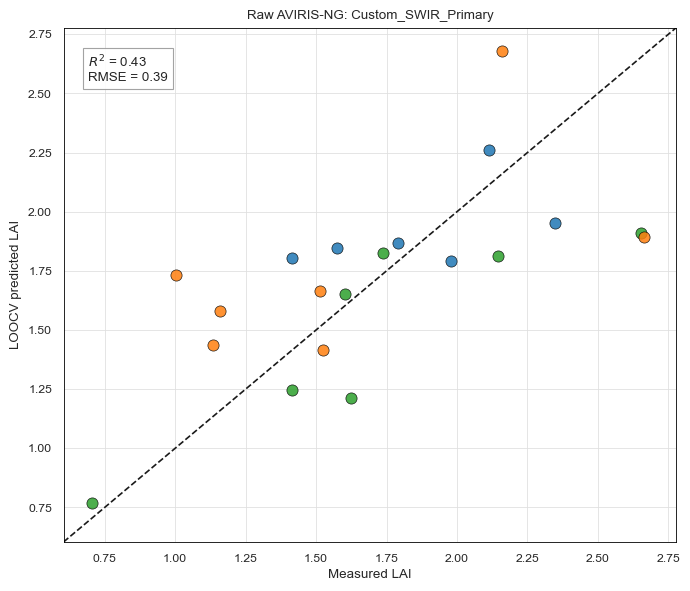

In [8]:
## C4. Plot the fixed SWIR LAI model

pred = primary_eval["LOOCV_pred"]
fig, ax = plt.subplots(figsize=(7, 6))

class_map = {"BY_2006": "#1f77b4", "BY_2016": "#2ca02c", "BY_2017_16": "#2ca02c", "BY_2019": "#ff7f0e", "BY_2020": "#ff7f0e"}
for site in np.unique(source_site):
    m = source_site == site
    ax.scatter(y_n20[m], pred[m], s=65, color=class_map.get(site, "0.5"), edgecolor="black", linewidth=0.5, alpha=0.85)

lims = [min(y_n20.min(), pred.min()) - 0.1, max(y_n20.max(), pred.max()) + 0.1]
ax.plot(lims, lims, "k--", linewidth=1.2); ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("Measured LAI"); ax.set_ylabel("LOOCV predicted LAI")
ax.set_title("Raw AVIRIS-NG: Custom_SWIR_Primary")
ax.text(0.04, 0.95, f"$R^2$ = {primary_eval['LOOCV_R2']:.2f}\nRMSE = {primary_eval['LOOCV_RMSE']:.2f}",
        transform=ax.transAxes, va="top", bbox=dict(facecolor="white", edgecolor="0.6", alpha=0.9))
ax.grid(True, color="0.88", linewidth=0.6); plt.tight_layout(); plt.show()